In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('vgsales.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Saving vgsales.csv to vgsales (1).csv
Dataset loaded successfully!
Dataset Shape: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [3]:

# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Unique values
print("\nUnique Genres:")
print(df['Genre'].unique())

print("\nUnique Platforms:", df['Platform'].nunique())

print("\nUnique Publishers:", df['Publisher'].nunique())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB

Statistical Summary:


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000



Column Names:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

Missing Values:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Duplicate Rows: 0

Unique Genres:
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']

Unique Platforms: 31

Unique Publishers: 578


In [4]:

# Create a copy of the original dataset
df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove rows where important information is missing
df_clean = df_clean.dropna(subset=['Name', 'Genre', 'Platform', 'Year', 'Global_Sales'])

# Fill missing publisher names
df_clean['Publisher'] = df_clean['Publisher'].fillna('Unknown')

# Convert Year into integer format
df_clean['Year'] = df_clean['Year'].astype(int)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

# Display cleaned dataset details
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

display(df_clean.head())


Missing values before cleaning:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Missing values after cleaning:
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

Original Dataset Shape: (16598, 11)
Cleaned Dataset Shape: (16327, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [5]:

print("Total Video Games:", df_clean['Name'].nunique())

print("Total Platforms:", df_clean['Platform'].nunique())

print("Total Genres:", df_clean['Genre'].nunique())

print("Total Publishers:", df_clean['Publisher'].nunique())

print("\nTotal Global Sales:",
      round(df_clean['Global_Sales'].sum(), 2), "million units")

print("Average Global Sales:",
      round(df_clean['Global_Sales'].mean(), 2), "million units")

print("Highest Global Sales:",
      df_clean['Global_Sales'].max(), "million units")

print("\nSales Statistics:")
display(df_clean['Global_Sales'].describe())


Total Video Games: 11360
Total Platforms: 31
Total Genres: 12
Total Publishers: 576

Total Global Sales: 8820.36 million units
Average Global Sales: 0.54 million units
Highest Global Sales: 82.74 million units

Sales Statistics:


,Global_Sales
count,16327.000000
mean,0.540232
std,1.565732
min,0.010000
25%,0.060000
50%,0.170000
75%,0.480000
max,82.740000


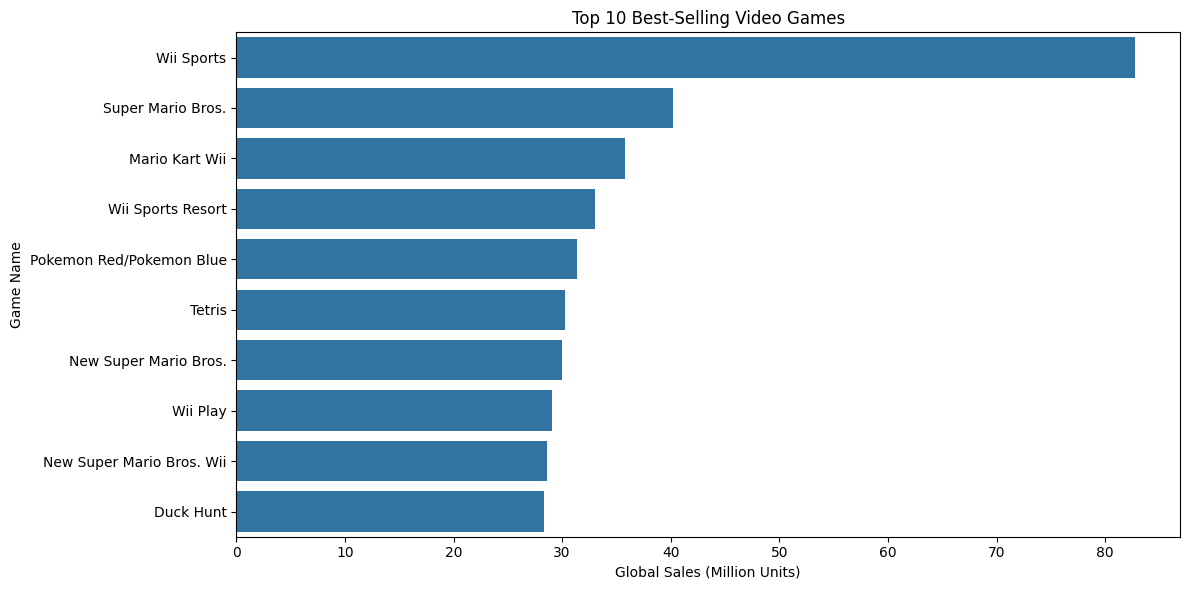

In [6]:

top_games = df_clean.nlargest(10, 'Global_Sales')

plt.figure(figsize=(12, 6))
sns.barplot(data=top_games, x='Global_Sales', y='Name')
plt.title('Top 10 Best-Selling Video Games')
plt.xlabel('Global Sales (Million Units)')
plt.ylabel('Game Name')
plt.tight_layout()
plt.savefig('top_10_games.png')
plt.show()


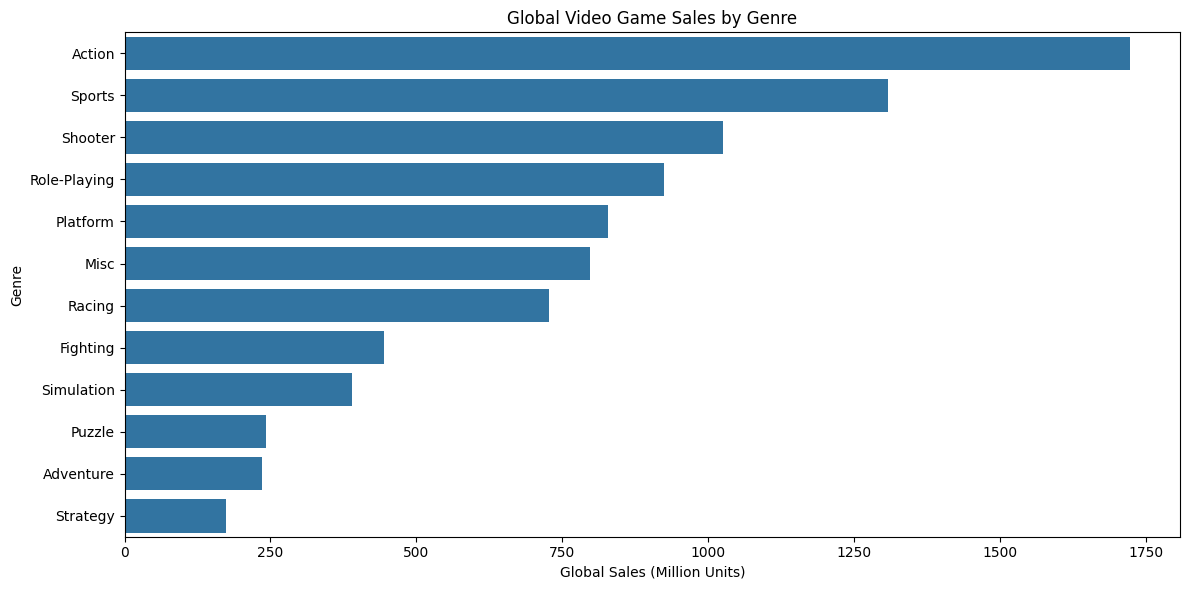

In [7]:

genre_sales = df_clean.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_sales.values, y=genre_sales.index)
plt.title('Global Video Game Sales by Genre')
plt.xlabel('Global Sales (Million Units)')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('sales_by_genre.png')
plt.show()


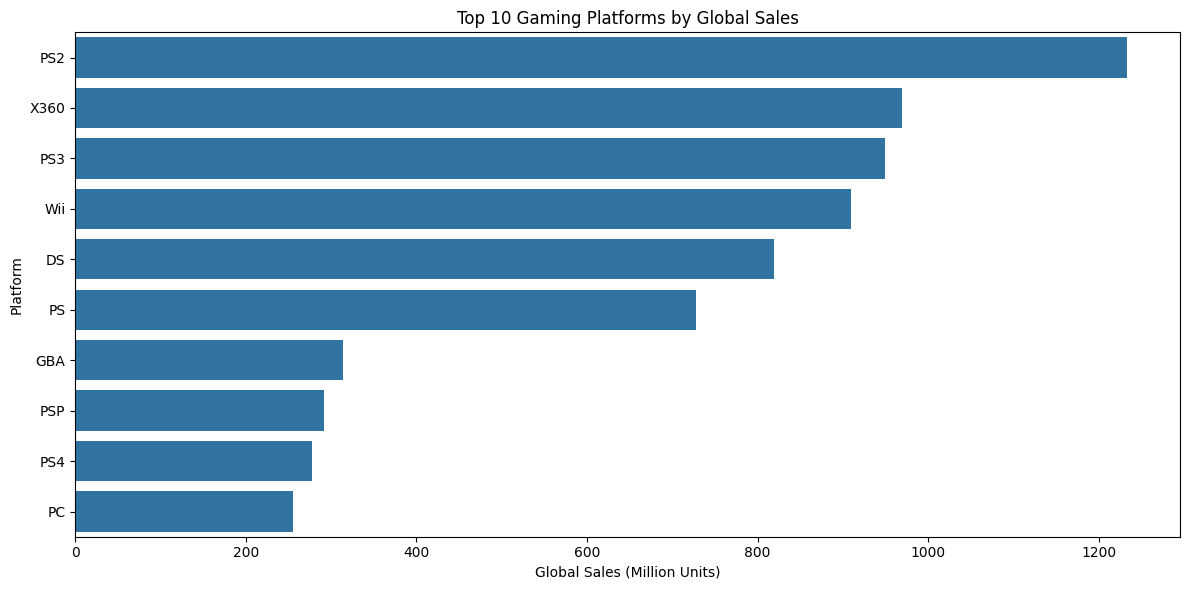

In [8]:

platform_sales = df_clean.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=platform_sales.values, y=platform_sales.index)
plt.title('Top 10 Gaming Platforms by Global Sales')
plt.xlabel('Global Sales (Million Units)')
plt.ylabel('Platform')
plt.tight_layout()
plt.savefig('top_10_platforms.png')
plt.show()


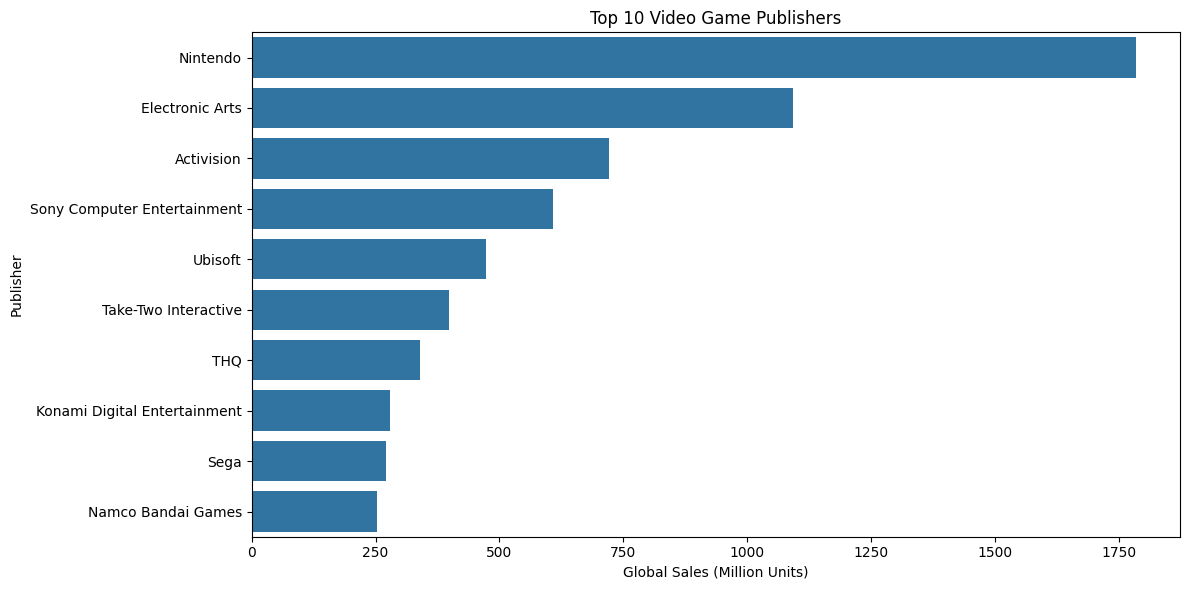

In [9]:

publisher_sales = df_clean.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=publisher_sales.values, y=publisher_sales.index)
plt.title('Top 10 Video Game Publishers')
plt.xlabel('Global Sales (Million Units)')
plt.ylabel('Publisher')
plt.tight_layout()
plt.savefig('top_10_publishers.png')
plt.show()


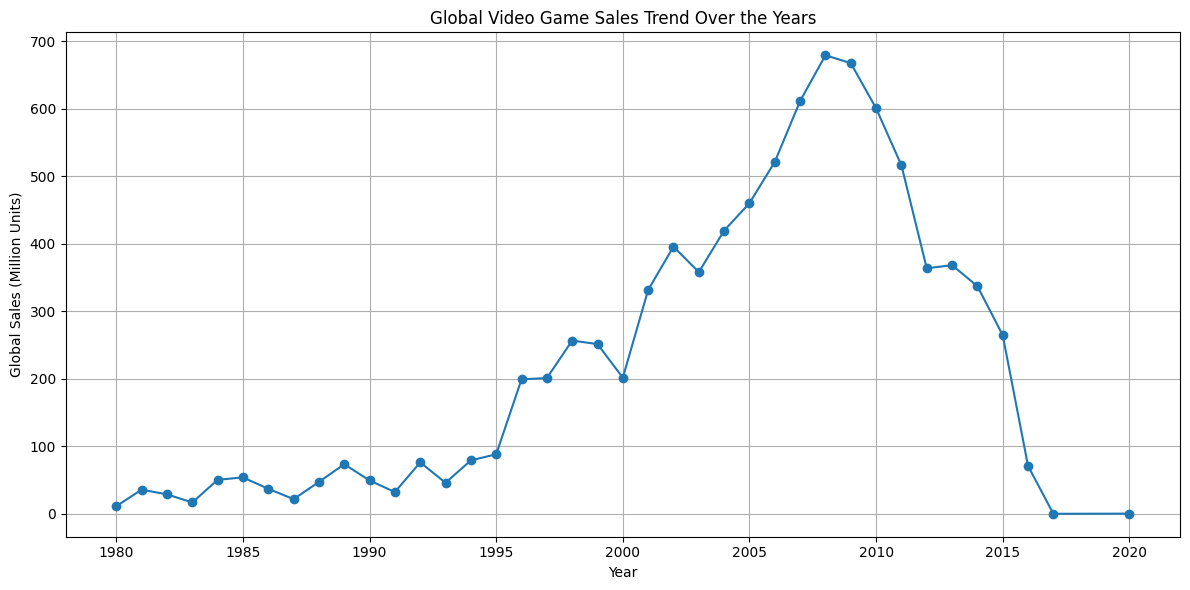

In [10]:

yearly_sales = df_clean.groupby('Year')['Global_Sales'].sum()

plt.figure(figsize=(12, 6))
plt.plot(yearly_sales.index, yearly_sales.values, marker='o')
plt.title('Global Video Game Sales Trend Over the Years')
plt.xlabel('Year')
plt.ylabel('Global Sales (Million Units)')
plt.grid(True)
plt.tight_layout()
plt.savefig('global_sales_trend.png')
plt.show()


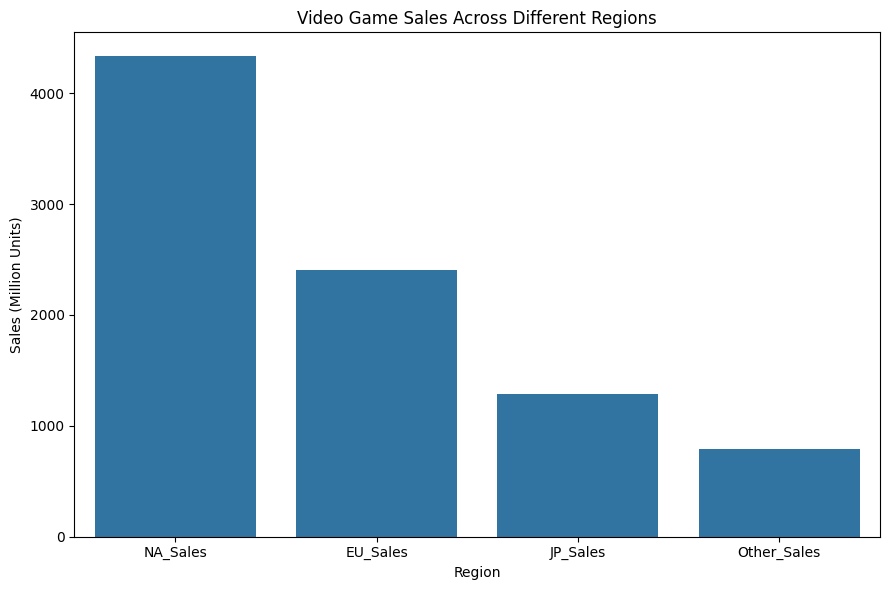

In [11]:

regional_sales = df_clean[
    ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
].sum()

plt.figure(figsize=(9, 6))
sns.barplot(x=regional_sales.index, y=regional_sales.values)
plt.title('Video Game Sales Across Different Regions')
plt.xlabel('Region')
plt.ylabel('Sales (Million Units)')
plt.tight_layout()
plt.savefig('regional_sales_comparison.png')
plt.show()


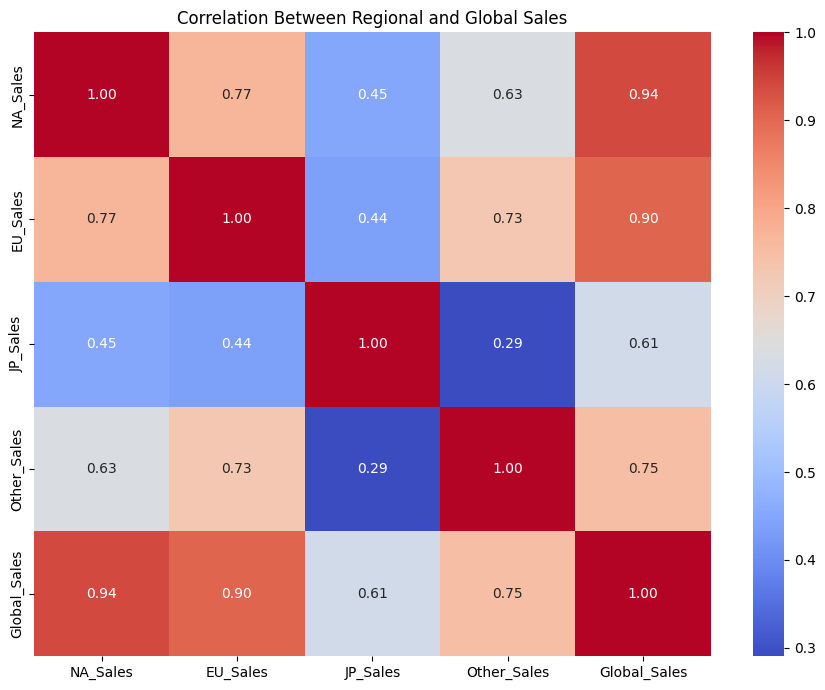

In [12]:

sales_columns = [
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales'
]

correlation = df_clean[sales_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Regional and Global Sales')
plt.tight_layout()
plt.savefig('sales_correlation_heatmap.png')
plt.show()


In [13]:

best_game = df_clean.loc[df_clean['Global_Sales'].idxmax()]

best_genre = (
    df_clean.groupby('Genre')['Global_Sales']
    .sum().idxmax()
)

best_platform = (
    df_clean.groupby('Platform')['Global_Sales']
    .sum().idxmax()
)

best_publisher = (
    df_clean.groupby('Publisher')['Global_Sales']
    .sum().idxmax()
)

best_region = regional_sales.idxmax()

print("KEY FINDINGS")
print("-" * 40)

print(f"1. Best-selling game: {best_game['Name']}")
print(f"   Global sales: {best_game['Global_Sales']} million units")

print(f"2. Highest-selling genre: {best_genre}")
print(f"3. Highest-selling platform: {best_platform}")
print(f"4. Highest-selling publisher: {best_publisher}")
print(f"5. Highest-selling region: {best_region}")

print(
    "6. Total global sales:",
    round(df_clean['Global_Sales'].sum(), 2),
    "million units"
)

print(
    "7. Average global sales:",
    round(df_clean['Global_Sales'].mean(), 2),
    "million units"
)


KEY FINDINGS
----------------------------------------
1. Best-selling game: Wii Sports
   Global sales: 82.74 million units
2. Highest-selling genre: Action
3. Highest-selling platform: PS2
4. Highest-selling publisher: Nintendo
5. Highest-selling region: NA_Sales
6. Total global sales: 8820.36 million units
7. Average global sales: 0.54 million units


In [14]:

# Save cleaned dataset
df_clean.to_csv('cleaned_video_game_sales.csv', index=False)

# Save summary results
genre_sales.to_csv('genre_sales_summary.csv')
platform_sales.to_csv('platform_sales_summary.csv')
publisher_sales.to_csv('publisher_sales_summary.csv')
yearly_sales.to_csv('yearly_sales_summary.csv')
regional_sales.to_csv('regional_sales_summary.csv')

# Save correlation results
correlation.to_csv('sales_correlation_results.csv')

print("All project files saved successfully!")


All project files saved successfully!


In [15]:

import os
import zipfile
from google.colab import files

project_files = [
    'cleaned_video_game_sales.csv',
    'genre_sales_summary.csv',
    'platform_sales_summary.csv',
    'publisher_sales_summary.csv',
    'yearly_sales_summary.csv',
    'regional_sales_summary.csv',
    'sales_correlation_results.csv',
    'top_10_games.png',
    'sales_by_genre.png',
    'top_10_platforms.png',
    'top_10_publishers.png',
    'global_sales_trend.png',
    'regional_sales_comparison.png',
    'sales_correlation_heatmap.png'
]

with zipfile.ZipFile('Video_Game_Sales_EDA_Results.zip', 'w') as zip_file:
    for filename in project_files:
        if os.path.exists(filename):
            zip_file.write(filename)

files.download('Video_Game_Sales_EDA_Results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>